In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import abc, gc, os, random, re, sys, time, traceback
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stable_baselines3 as sb
from stable_baselines3.common.env_util import make_vec_env
from typing import SupportsFloat, Any
import gymnasium as gym
from gymnasium.core import ActType, ObsType

import faiss
import sklearn
import tqdm
import chime

import torch
from torch.nn import functional as F
from torch.utils import data
from torch import optim

In [7]:
from data_loaders import KuaiRecData
from rs_algorithm import RLModelS2Solution, Evaluator, SimulationEvaluator

In [5]:
data_model = KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [8]:
solution = RLModelS2Solution(data_model)

In [9]:
evaluator = Evaluator()
evaluator.evaluate(solution)

{'train': {'hit_rate_at_k': np.float64(0.72),
  'precision_at_k': np.float64(0.118),
  'recall_at_k': np.float64(0.118),
  'ndcg_at_k': np.float64(0.11350358879153831),
  'mrr_at_k': np.float64(0.24403968253968253)},
 'test': {'hit_rate_at_k': np.float64(0.27),
  'precision_at_k': np.float64(0.032),
  'recall_at_k': np.float64(0.032),
  'ndcg_at_k': np.float64(0.030784887326589794),
  'mrr_at_k': np.float64(0.07615873015873016)}}

In [18]:
sim_evaluator = SimulationEvaluator(data_model, n_sample_users=10)

In [26]:
results = sim_evaluator.evaluate_simulation(solution, n_time_stamps=300, top_k=10)

C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\dshcrs_solution.py:6: RuntimeWarning: Mean of empty slice
  from stable_baselines3.common.env_util import make_vec_env
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\dshcrs_solution.py:6: RuntimeWarning: Mean of empty slice
  from stable_baselines3.common.env_util import make_vec_env
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\src\rs_algorithm\dshcrs_solution.py:6: RuntimeWarning: Mean of empty slice
  from stable_baselines3.common.env_util import make_vec_env
C:\Beryllium Base\WORKSPACES\MTECH\RS-project\.venv\Lib\site-packages\numpy\_c

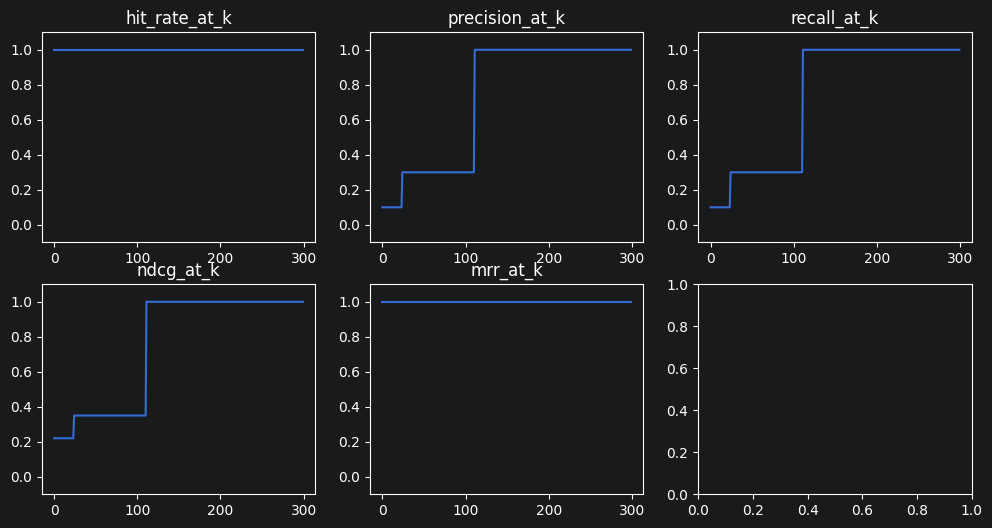

In [30]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, (k, v) in zip(axs.ravel(), results[3].items()):
    ax.plot(v)
    ax.set_title(k)
    ax.set_ylim(-0.1, 1.1)

In [33]:
aggregate = {'hit_rate_at_k': [],
             'precision_at_k': [],
             'recall_at_k': [],
             'ndcg_at_k': [],
             'mrr_at_k': []}

for t in range(300):
    for m in ['hit_rate_at_k', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'mrr_at_k']:
        aggregate[m].append(np.mean([r[m][t] for r in results]))

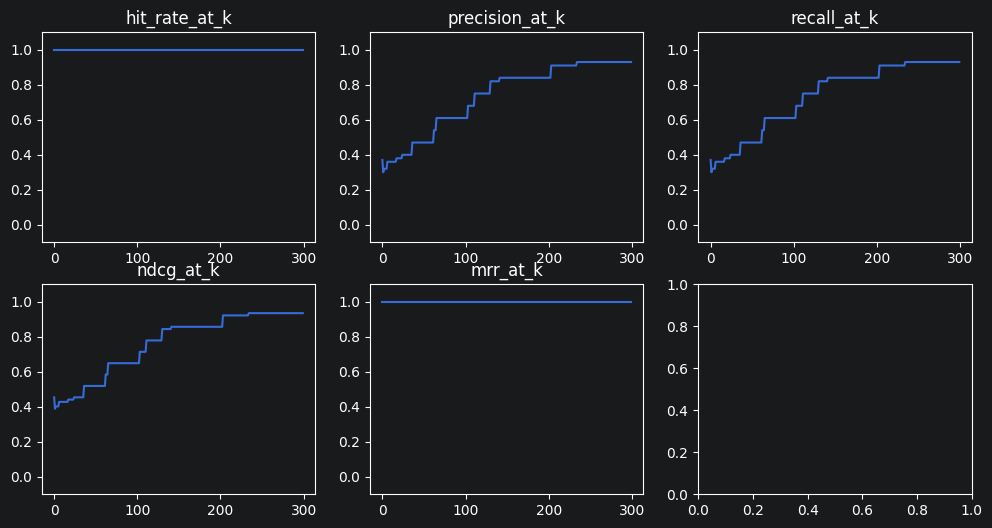

In [34]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, (k, v) in zip(axs.ravel(), aggregate.items()):
    ax.plot(v)
    ax.set_title(k)
    ax.set_ylim(-0.1, 1.1)